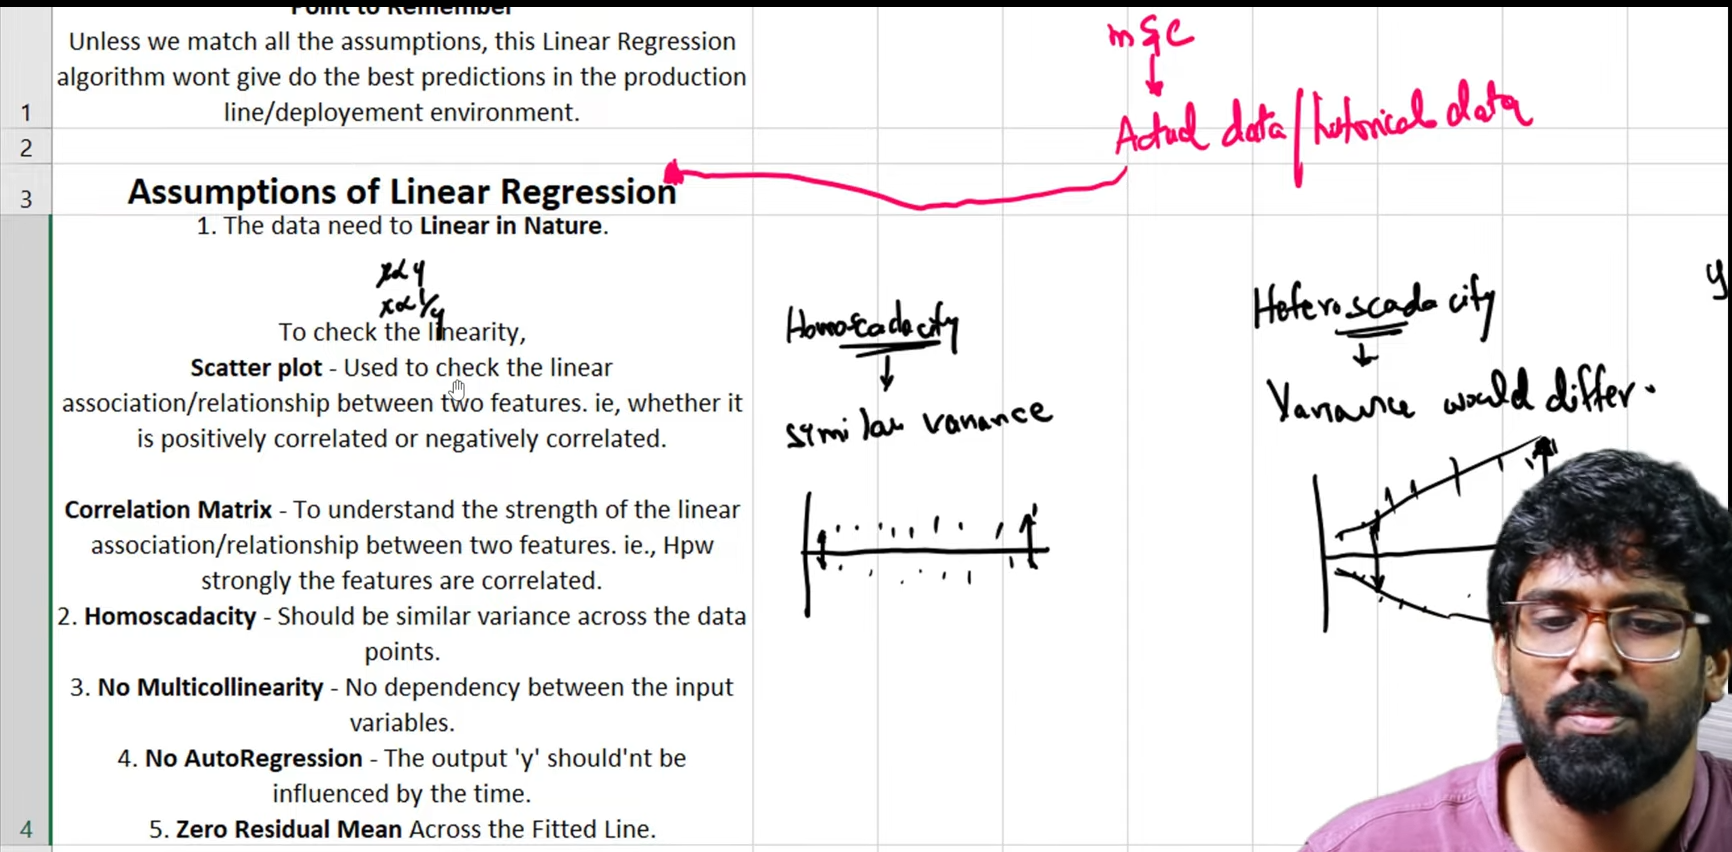

## 1. Import Necessary libraries

In [4]:
import pandas as pd
from matplotlib import pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split

import warnings
warnings.filterwarnings("ignore")

## 2. Import Dataset

In [5]:
cars_data = pd.read_csv(filepath_or_buffer = "Cars.csv")
cars_data

,HP,MPG,VOL,SP,WT
0,49,53.700681,89,104.185353,28.762059
1,55,50.013401,92,105.461264,30.466833
2,55,50.013401,92,105.461264,30.193597
3,70,45.696322,92,113.461264,30.632114
4,53,50.504232,92,104.461264,29.889149
...,...,...,...,...,...
76,322,36.900000,50,169.598513,16.132947
77,238,19.197888,115,150.576579,37.923113
78,263,34.000000,50,151.598513,15.769625
79,295,19.833733,119,167.944460,39.423099


## 3. Data Understanding

### 3.1 perform Initial Investigation on the data

In [6]:
cars_data.shape

(81, 5)

In [7]:
cars_data.isna().sum()

HP     0
MPG    0
VOL    0
SP     0
WT     0
dtype: int64

In [8]:
cars_data.dtypes

HP       int64
MPG    float64
VOL      int64
SP     float64
WT     float64
dtype: object

In [9]:
cars_data.describe()

,HP,MPG,VOL,SP,WT
count,81.000000,81.000000,81.000000,81.000000,81.000000
mean,117.469136,34.422076,98.765432,121.540272,32.412577
std,57.113502,9.131445,22.301497,14.181432,7.492813
min,49.000000,12.101263,50.000000,99.564907,15.712859
25%,84.000000,27.856252,89.000000,113.829145,29.591768
50%,100.000000,35.152727,101.000000,118.208698,32.734518
75%,140.000000,39.531633,113.000000,126.404312,37.392524
max,322.000000,53.700681,160.000000,169.598513,52.997752


## Now, let's check for the Assumptions

## Test 1: Linearity Test

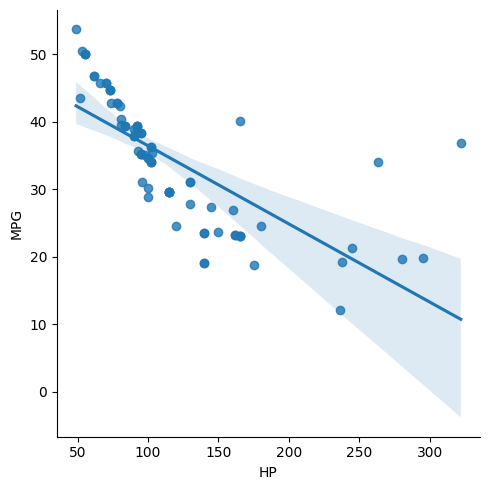

In [10]:
sns.lmplot(data = cars_data, x="HP", y="MPG",)

#### Note:
**Intha linear line la ella dots yum antha line kitta irrutha than prediction easy ah irrukum intha case la scatter ah irrku so konjam kastam ma irrukum.**

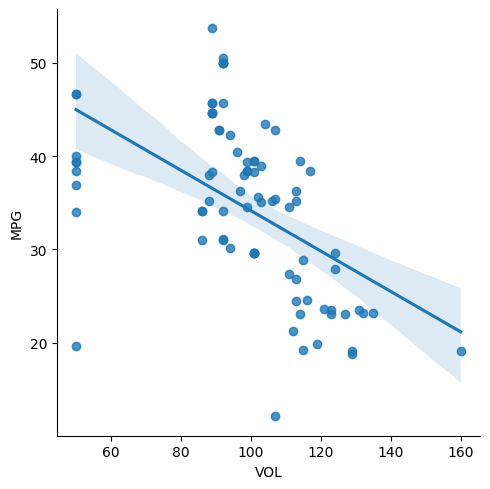

In [11]:
sns.lmplot(data = cars_data, x="VOL", y="MPG",)

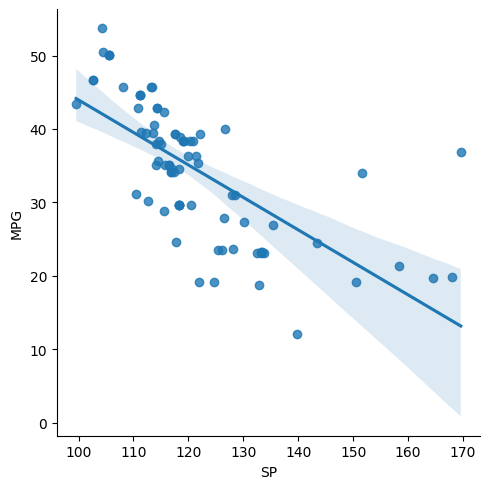

In [12]:
sns.lmplot(data = cars_data, x="SP", y="MPG",)

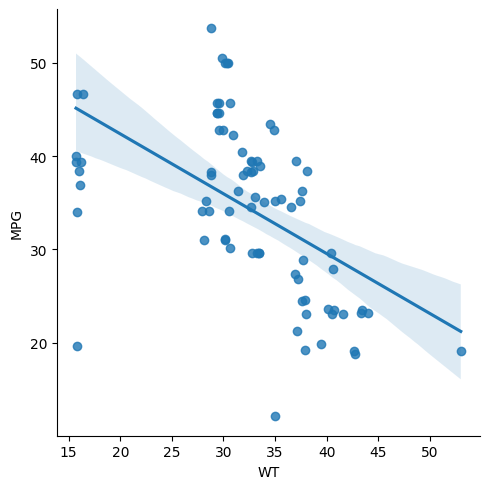

In [13]:
sns.lmplot(data = cars_data, x="WT", y="MPG",)

#### Test 1 Linearity Failed.

## Test 2: Normality Test

(array([15., 35.,  9.,  6.,  9.,  0.,  2.,  2.,  1.,  2.]),
 array([ 49. ,  76.3, 103.6, 130.9, 158.2, 185.5, 212.8, 240.1, 267.4,
        294.7, 322. ]),
 <BarContainer object of 10 artists>)

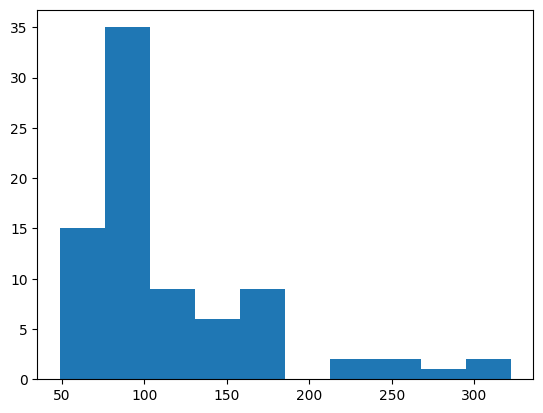

In [14]:
plt.hist(cars_data["HP"])

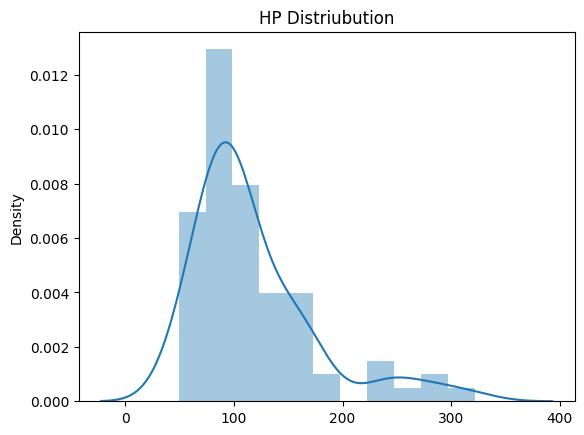

In [15]:
sns.distplot(x=cars_data["HP"])
plt.title("HP Distriubution")
plt.show()

(array([ 8., 12., 32., 10., 10.,  2.,  1.,  2.,  1.,  3.]),
 array([ 99.56490661, 106.56826723, 113.57162785, 120.57498847,
        127.57834909, 134.58170971, 141.58507032, 148.58843094,
        155.59179156, 162.59515218, 169.5985128 ]),
 <BarContainer object of 10 artists>)

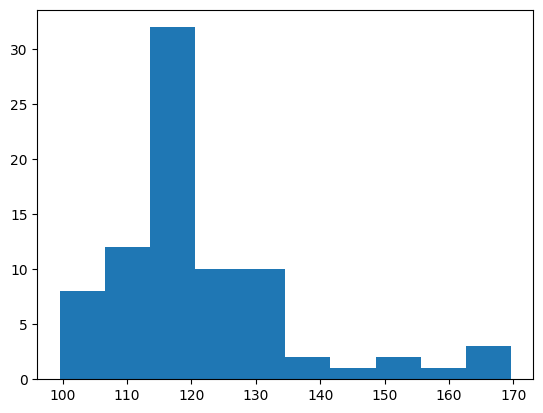

In [16]:
plt.hist(cars_data["SP"])

#### Note:
**Ithuku name sqide nu solluvom tail of the chat romba kutty ya irruku, prediction ithu kastam ma irrukum**

(array([ 9.,  0.,  0., 22., 20., 15.,  8.,  6.,  0.,  1.]),
 array([ 50.,  61.,  72.,  83.,  94., 105., 116., 127., 138., 149., 160.]),
 <BarContainer object of 10 artists>)

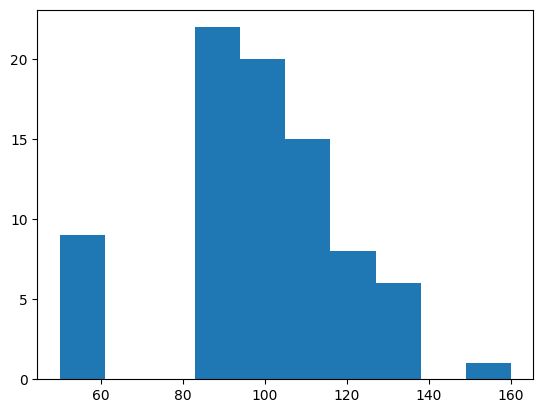

In [17]:
plt.hist(cars_data["VOL"])

(array([ 9.,  0.,  0., 22., 19., 18.,  7.,  5.,  0.,  1.]),
 array([15.71285853, 19.44134791, 23.1698373 , 26.89832668, 30.62681606,
        34.35530544, 38.08379483, 41.81228421, 45.54077359, 49.26926298,
        52.99775236]),
 <BarContainer object of 10 artists>)

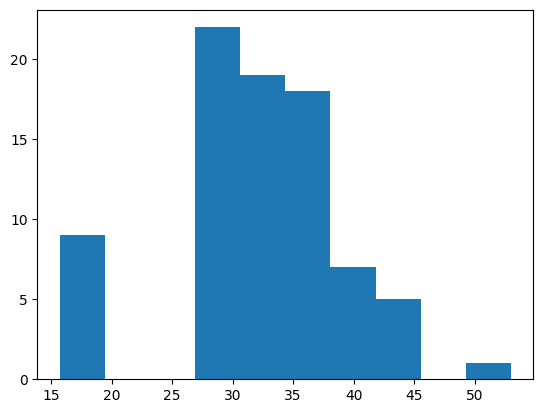

In [18]:
plt.hist(cars_data["WT"])

### Test 2 Normality also Failed

### Test 3 - Multicollinearity Test

In [19]:
corr_matrix = cars_data.corr()
corr_matrix

,HP,MPG,VOL,SP,WT
HP,1.000000,-0.725038,0.077459,0.973848,0.076513
MPG,-0.725038,1.000000,-0.529057,-0.687125,-0.526759
VOL,0.077459,-0.529057,1.000000,0.102170,0.999203
SP,0.973848,-0.687125,0.102170,1.000000,0.102439
WT,0.076513,-0.526759,0.999203,0.102439,1.000000


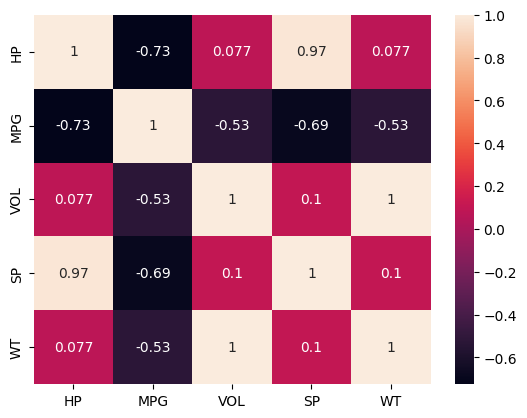

In [20]:
sns.heatmap(data = corr_matrix,annot=True)
plt.show()

### Test 3 - There is Multicollinearity in the Data

### Test 4 - AutoRegression Passed

**Note : AutoRegression na kuduthuruka data set la Time, date and weather ippidi lam columns irruka kudathu. so intha data set la appidi yathuvum illa so intha test pass.**

## 4. Data Preparation

In [21]:
cars_data

,HP,MPG,VOL,SP,WT
0,49,53.700681,89,104.185353,28.762059
1,55,50.013401,92,105.461264,30.466833
2,55,50.013401,92,105.461264,30.193597
3,70,45.696322,92,113.461264,30.632114
4,53,50.504232,92,104.461264,29.889149
...,...,...,...,...,...
76,322,36.900000,50,169.598513,16.132947
77,238,19.197888,115,150.576579,37.923113
78,263,34.000000,50,151.598513,15.769625
79,295,19.833733,119,167.944460,39.423099


In [22]:
X = cars_data[["HP","VOL","SP","WT"]]
X

,HP,VOL,SP,WT
0,49,89,104.185353,28.762059
1,55,92,105.461264,30.466833
2,55,92,105.461264,30.193597
3,70,92,113.461264,30.632114
4,53,92,104.461264,29.889149
...,...,...,...,...
76,322,50,169.598513,16.132947
77,238,115,150.576579,37.923113
78,263,50,151.598513,15.769625
79,295,119,167.944460,39.423099


In [23]:
y = cars_data["MPG"]
y

0     53.700681
1     50.013401
2     50.013401
3     45.696322
4     50.504232
        ...    
76    36.900000
77    19.197888
78    34.000000
79    19.833733
80    12.101263
Name: MPG, Length: 81, dtype: float64

### There is nothing to prepare because all features are numeric.

## 5. Model Building

In [24]:
linear_model  = LinearRegression()

In [25]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size= 0.20, random_state= 15, shuffle=True)

In [41]:
X_train

,HP,VOL,SP,WT
42,102,92,117.461264,30.527427
46,100,111,118.208698,36.498617
43,95,88,114.093383,28.343976
14,66,89,108.185353,29.347279
79,295,119,167.944460,39.423099
...,...,...,...,...
28,52,104,99.564907,34.483207
0,49,89,104.185353,28.762059
5,70,89,113.185353,29.591768
12,92,99,122.105055,32.813592


In [42]:
y_train

42    34.070668
46    34.561499
43    35.152727
14    45.734893
79    19.833733
        ...    
28    43.469434
0     53.700681
5     45.696322
12    39.354094
72    23.203569
Name: MPG, Length: 64, dtype: float64

In [43]:
X_test

,HP,VOL,SP,WT
75,175,129,132.864163,42.778219
30,84,114,113.484609,37.042350
36,90,88,114.093383,28.754000
59,100,115,115.576579,37.662874
68,165,123,133.312342,40.472042
77,238,115,150.576579,37.923113
9,80,94,115.645204,30.920154
70,280,50,164.598513,15.823060
20,92,99,119.105055,32.324650
73,140,160,124.715241,52.997752


In [44]:
y_test

75    18.762837
30    39.431235
36    37.958743
59    28.860225
68    23.103172
77    19.197888
9     42.299078
70    19.678507
20    38.411003
73    19.086341
25    38.411003
33    36.285456
65    40.050000
18    42.789909
67    23.103172
3     45.696322
54    26.852279
Name: MPG, dtype: float64

## 6. Model Training

In [49]:
linear_model.fit(X_train,y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [50]:
linear_model.intercept_

np.float64(27.000522492020337)

In [51]:
linear_model.coef_

array([-0.21032701, -0.23045363,  0.45048273,  0.00970423])

## 7.Model Testing

In [52]:
y_pred = linear_model.predict(X_train)
y_pred

array([37.55594975, 33.99263712, 38.41169237, 41.62899287, 13.56872349,
       28.41860667, 48.81518096, 41.43174922, 16.03983318, 28.8687628 ,
       28.40371634, 33.14191322, 28.6073823 , 40.47933147, 26.05517458,
       25.67593107, 33.14872746, 42.03228673, 48.81021506, 41.99950358,
       37.60771864, 24.31030381, 35.66084619, 38.24884927, 36.22328811,
       37.73239767, 35.07414056, 42.03340158, 33.77393613, 28.0613885 ,
       49.25673145, 37.13933331, 35.45726232, 37.04841699, 21.33174872,
       23.13750587, 42.03493827, 33.14893863, 33.14656578, 35.34699749,
       38.67167728, 26.07544732, 35.91046568, 29.93749473, 41.50845437,
       35.7814932 , 38.02963632, 38.66439341, 36.61810552, 41.5106484 ,
       41.50830789, 24.56888603, 37.52007609, 39.42750511, 36.96400464,
       49.261007  , 35.44986937, 22.345018  , 38.80893812, 37.28324461,
       43.39694195, 43.04247107, 40.16017789, 22.90568094])

#### Note: 

**predict la eppovom output value "y" pass panna kudathu "x" than pass pannanum**

## 8. Model Evaluation

In [53]:
error = y_train - y_pred
error

42    -3.485281
46     0.568862
43    -3.258965
14     4.105900
79     6.265010
        ...    
28     6.186189
0     10.303739
5      2.653851
12    -0.806084
72     0.297888
Name: MPG, Length: 64, dtype: float64

In [54]:
error.mean()

np.float64(3.497202527569243e-15)

In [63]:
from sklearn.metrics import mean_absolute_error,mean_squared_error,root_mean_squared_error,r2_score

In [56]:
mean_absolute_error(y_train, y_pred) # Same Units

3.4562481903371043

In [59]:
mean_squared_error(y_train, y_pred) # Squared o/p Units

20.164168967952364

In [62]:
root_mean_squared_error(y_train, y_pred) # Normalize the Units

4.490453091610284

In [64]:
r2_score(y_train, y_pred)

0.7419492869833406

In [70]:
#pip install statsmodels

### Note:
* Ithu vanthu **linear_model = LinearRegression()** athu mari **linear_stats_model = smf.ols(formula = "MPG ~ HP+VOL+SP+WT", data = cars_data).fit()** ithu oru model 

In [67]:
import statsmodels.formula.api as smf

In [68]:
cars_data.head()

,HP,MPG,VOL,SP,WT
0,49,53.700681,89,104.185353,28.762059
1,55,50.013401,92,105.461264,30.466833
2,55,50.013401,92,105.461264,30.193597
3,70,45.696322,92,113.461264,30.632114
4,53,50.504232,92,104.461264,29.889149


## To see Adjusted R2 Score, we are using OLS technique from Stats Models Formula

In [85]:
linear_stats_model = smf.ols(formula = "MPG ~ HP", data = cars_data).fit()
linear_stats_model.predict(X_train)

42    36.215272
46    36.447113
43    37.026718
14    40.388423
79    13.842541
        ...    
28    42.011316
0     42.359078
5     39.924740
12    37.374480
72    29.260019
Length: 64, dtype: float64

In [86]:
print("R2 Score:", linear_stats_model.rsquared.round(4),"\nAdjusted R2 Scored:", linear_stats_model.rsquared_adj.round(4))

R2 Score: 0.5257 
Adjusted R2 Scored: 0.5197


In [78]:
linear_stats_model = smf.ols(formula = "MPG ~ HP+VOL", data = cars_data).fit()

In [79]:
print("R2 Score:", linear_stats_model.rsquared.round(4),"\nAdjusted R2 Scored:", linear_stats_model.rsquared_adj.round(4))

R2 Score: 0.7507 
Adjusted R2 Scored: 0.7443


In [80]:
linear_stats_model = smf.ols(formula = "MPG ~ HP+VOL+SP", data = cars_data).fit()

In [81]:
print("R2 Score:", linear_stats_model.rsquared.round(4),"\nAdjusted R2 Scored:", linear_stats_model.rsquared_adj.round(4))

R2 Score: 0.7704 
Adjusted R2 Scored: 0.7614


In [69]:
linear_stats_model = smf.ols(formula = "MPG ~ HP+VOL+SP+WT", data = cars_data).fit()

In [75]:
print("R2 Score:", linear_stats_model.rsquared.round(4),"\nAdjusted R2 Scored:", linear_stats_model.rsquared_adj.round(4))

R2 Score: 0.7705 
Adjusted R2 Scored: 0.7585


#### Note:

* **R2 Score: 0.7705**
* **Adjusted R2 Scored: 0.7585**

* R2 Score ah vida Adjusted R2 Score kammi ya agiruku ithu puropse enna?? oru oru input features add panna panna R2 Score increase agum and Adjusted R2 Score decrease agum

#### Conculsion:
**R2 score is keep increasing no matter how many inputs you increased, but Ajusted R2 Score will not keep increasing if you keep increasing the number of input features**

#### Note: Ithula 2 irruku 
* plt.scatter - inthu vanthu error column vanthu original data base la irrukathu itha add pannitu aprm ah x and y la values pass pannikalam
* sns.scatterplot - ithu appidi yathuvum panna vendam direct ah x and y la values pass pannikalam **sns.scatterplot( data=cars_data,x = "WT", y = error)**

**So ithula sns.scatterplot( data=cars_data,x = "WT", y = error) ithu than best.**

In [31]:
cars_data["error"] = error
cars_data

,HP,MPG,VOL,SP,WT,error
0,49,53.700681,89,104.185353,28.762059,10.258747
1,55,50.013401,92,105.461264,30.466833,7.624608
2,55,50.013401,92,105.461264,30.193597,7.734060
3,70,45.696322,92,113.461264,30.632114,3.157963
4,53,50.504232,92,104.461264,29.889149,8.331584
...,...,...,...,...,...,...
76,322,36.900000,50,169.598513,16.132947,15.617904
77,238,19.197888,115,150.576579,37.923113,1.298838
78,263,34.000000,50,151.598513,15.769625,7.863547
79,295,19.833733,119,167.944460,39.423099,7.517122


In [32]:
del cars_data["error"]

In [33]:
cars_data

,HP,MPG,VOL,SP,WT
0,49,53.700681,89,104.185353,28.762059
1,55,50.013401,92,105.461264,30.466833
2,55,50.013401,92,105.461264,30.193597
3,70,45.696322,92,113.461264,30.632114
4,53,50.504232,92,104.461264,29.889149
...,...,...,...,...,...
76,322,36.900000,50,169.598513,16.132947
77,238,19.197888,115,150.576579,37.923113
78,263,34.000000,50,151.598513,15.769625
79,295,19.833733,119,167.944460,39.423099



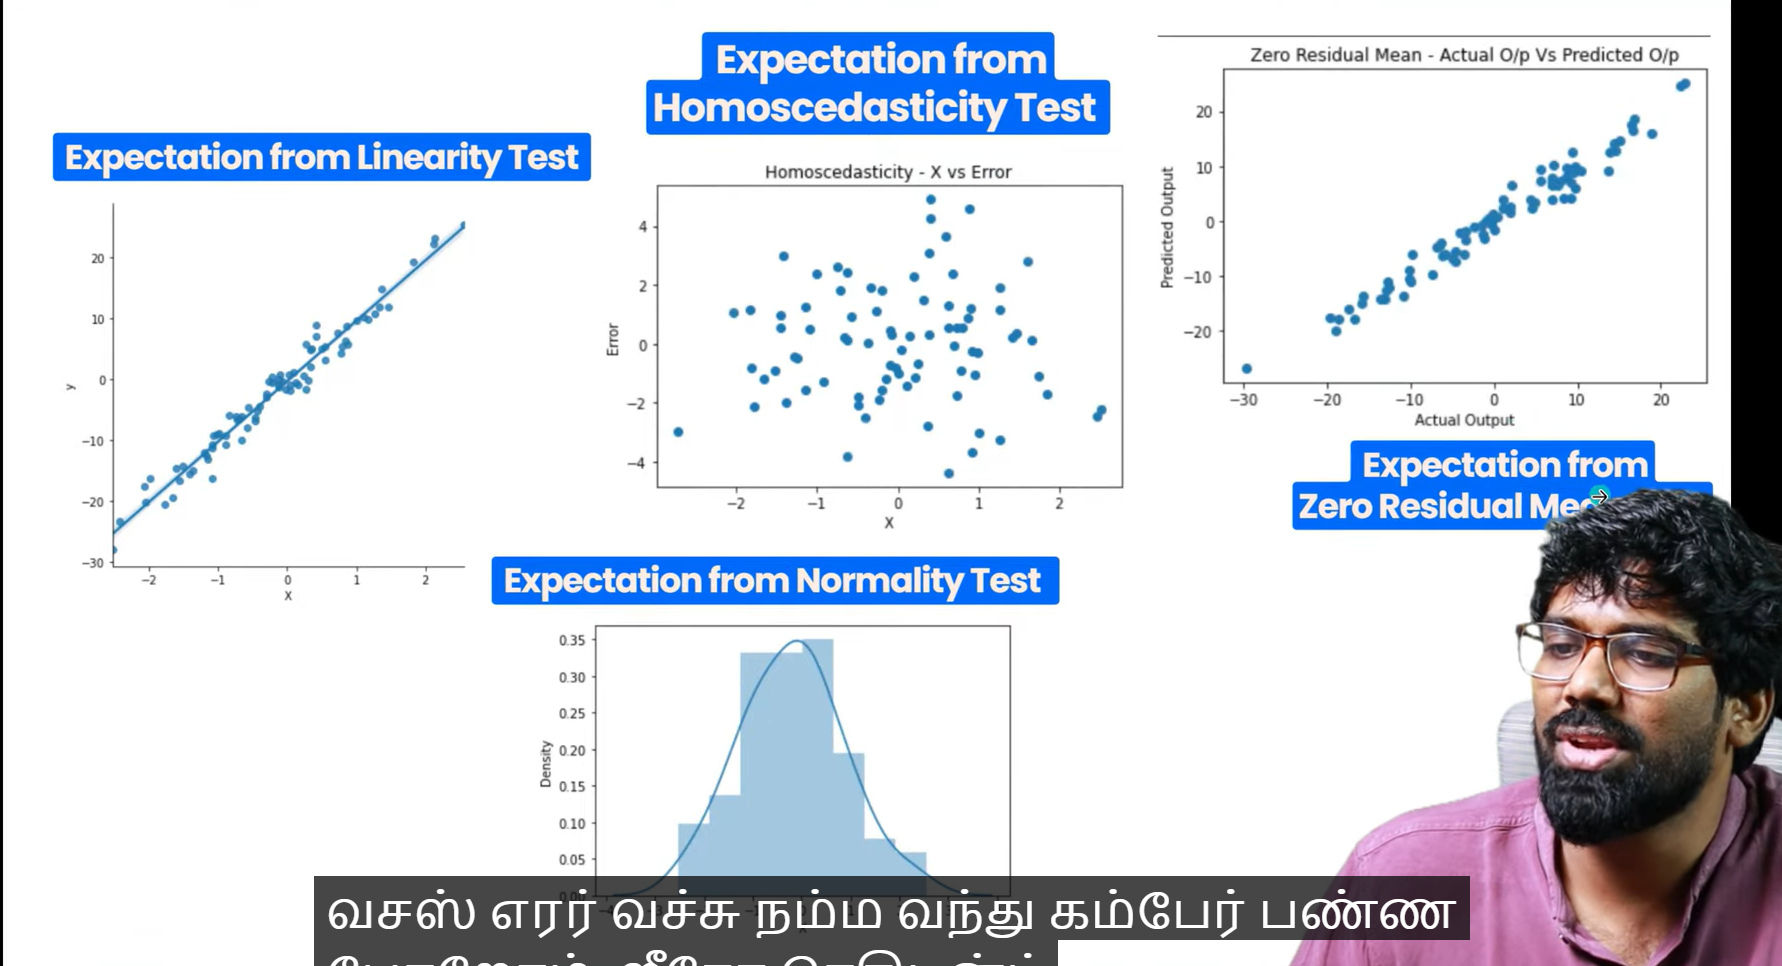

### Let's now perform Test 5: Homoscedasticity Test

ValueError: x and y must be the same size

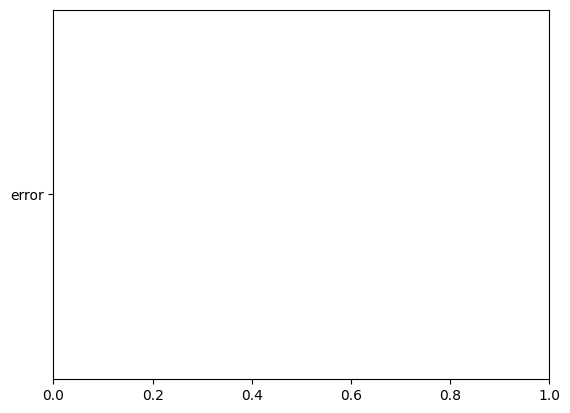

In [34]:
plt.scatter(data=cars_data, x = "HP", y = "error")

In [ ]:
sns.scatterplot( data=cars_data,x = "WT", y = error)
plt.show()

### Test 5 Homoscedasticity Test also Failed
**Ithu en failed na "MPG" oda antha value 0 irrukula athula irruthu down value vanthu -5 and Up value 15 ippidi scatter aga kudathu, onnu -5 to +5 irruthuchi na Homoscadasticity pass agum**

## Test 6: Zero Residual Mean Test

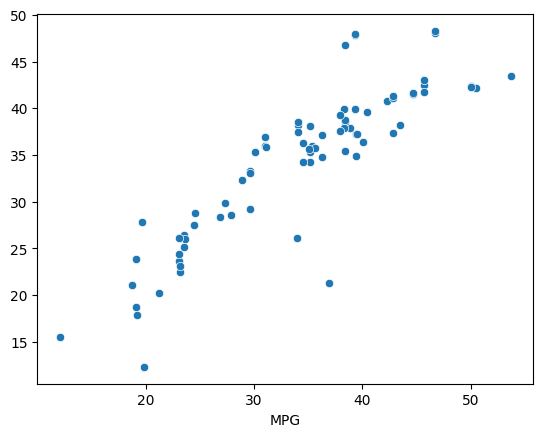

In [35]:
sns.scatterplot(x = cars_data["MPG"], y = y_pred)
plt.show()

### Test 6: Zero Residual Mean Test is also Failed

## 9. Model Deployment

In [36]:
from pickle import dump

In [37]:
dump(obj = linear_model,file = open(file = "linear_intelligence_file.pkl", mode='wb'))

In [38]:
from pickle import load

In [39]:
linear_intel_pkl = load(file = open(file = "linear_intelligence_file.pkl", mode='rb'))
linear_intel_pkl

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [40]:
linear_intel_pkl.predict(X)

array([43.44193477, 42.38879289, 42.27934147, 42.53835981, 42.17264802,
       43.02061916, 42.32536062, 48.07621852, 48.28120247, 40.79122814,
       41.52153227, 47.80956747, 39.95980269, 41.52757889, 41.76632332,
       41.6181448 , 41.15094046, 47.98605515, 41.30861046, 37.87127922,
       38.57706414, 37.35199705, 37.89770285, 39.5625144 , 39.93380662,
       46.73870908, 35.48165898, 38.78152504, 38.24861192, 36.00285298,
       34.84603989, 37.21630246, 37.13919796, 34.82541399, 37.22361389,
       37.53950097, 39.27144845, 38.24219888, 38.54286458, 35.9391722 ,
       34.2129755 , 35.36313259, 37.50473376, 38.07998482, 35.79651664,
       36.2613377 , 34.21826465, 35.59393404, 36.91805291, 33.31108154,
       33.21313413, 33.3023649 , 29.19864884, 27.52358579, 28.3207133 ,
       28.56722621, 35.81583602, 33.02108459, 35.37334971, 32.29909503,
       29.87685849, 28.76093817, 25.14188416, 26.47040896, 25.97651933,
       36.35652478, 26.0975912 , 23.6416178 , 24.39887199, 20.21

## THE END!!